In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('titanic.csv')

In [3]:
df.head()

,Cabin,Ticket,number,Survived
0,NaN,A/5 21171,5,0
1,C85,PC 17599,3,1
2,NaN,STON/O2. 3101282,6,1
3,C123,113803,3,1
4,NaN,373450,A,0


In [5]:
df["number"].unique()

array(['5', '3', '6', 'A', '2', '1', '4'], dtype=object)

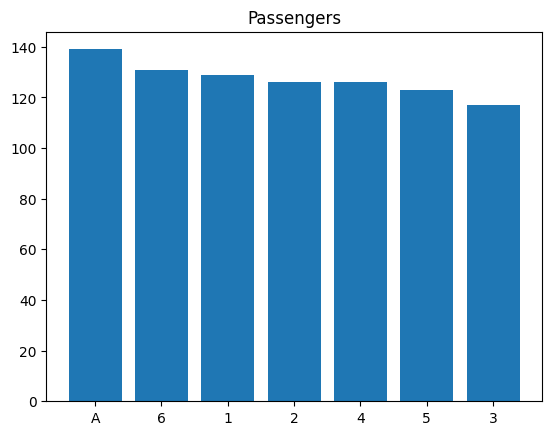

In [11]:
counts = df['number'].value_counts()
plt.bar(counts.index, counts.values)
plt.title('Passengers')
plt.show()


In [13]:
df['number_numerical'] = pd.to_numeric(df['number'],errors='coerce',downcast='integer')

In [15]:
df.head()

,Cabin,Ticket,number,Survived,number_numerical
0,NaN,A/5 21171,5,0,5.0
1,C85,PC 17599,3,1,3.0
2,NaN,STON/O2. 3101282,6,1,6.0
3,C123,113803,3,1,3.0
4,NaN,373450,A,0,NaN


In [16]:
df['number_categorical'] = np.where(df['number_numerical'].isnull(),df['number'],np.nan)

In [17]:
df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical
0,NaN,A/5 21171,5,0,5.0,NaN
1,C85,PC 17599,3,1,3.0,NaN
2,NaN,STON/O2. 3101282,6,1,6.0,NaN
3,C123,113803,3,1,3.0,NaN
4,NaN,373450,A,0,NaN,A


In [18]:
df['Cabin'].unique()

array([nan, 'C85', 'C123', 'E46', 'G6', 'C103', 'D56', 'A6',
       'C23 C25 C27', 'B78', 'D33', 'B30', 'C52', 'B28', 'C83', 'F33',
       'F G73', 'E31', 'A5', 'D10 D12', 'D26', 'C110', 'B58 B60', 'E101',
       'F E69', 'D47', 'B86', 'F2', 'C2', 'E33', 'B19', 'A7', 'C49', 'F4',
       'A32', 'B4', 'B80', 'A31', 'D36', 'D15', 'C93', 'C78', 'D35',
       'C87', 'B77', 'E67', 'B94', 'C125', 'C99', 'C118', 'D7', 'A19',
       'B49', 'D', 'C22 C26', 'C106', 'C65', 'E36', 'C54',
       'B57 B59 B63 B66', 'C7', 'E34', 'C32', 'B18', 'C124', 'C91', 'E40',
       'T', 'C128', 'D37', 'B35', 'E50', 'C82', 'B96 B98', 'E10', 'E44',
       'A34', 'C104', 'C111', 'C92', 'E38', 'D21', 'E12', 'E63', 'A14',
       'B37', 'C30', 'D20', 'B79', 'E25', 'D46', 'B73', 'C95', 'B38',
       'B39', 'B22', 'C86', 'C70', 'A16', 'C101', 'C68', 'A10', 'E68',
       'B41', 'A20', 'D19', 'D50', 'D9', 'A23', 'B50', 'A26', 'D48',
       'E58', 'C126', 'B71', 'B51 B53 B55', 'D49', 'B5', 'B20', 'F G63',
       'C62 C64',

In [19]:
df['cabin_num'] = df['Cabin'].str.extract('(\d+)')
df['Cabin_cut'] = df['Cabin'].str[0]

In [20]:
df.head(10)

,Cabin,Ticket,number,Survived,number_numerical,number_categorical,cabin_num,Cabin_cut
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,NaN
1,C85,PC 17599,3,1,3.0,NaN,85,C
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN
3,C123,113803,3,1,3.0,NaN,123,C
4,NaN,373450,A,0,NaN,A,NaN,NaN
5,NaN,330877,2,0,2.0,NaN,NaN,NaN
6,E46,17463,2,0,2.0,NaN,46,E
7,NaN,349909,5,0,5.0,NaN,NaN,NaN
8,NaN,347742,1,1,1.0,NaN,NaN,NaN
9,NaN,237736,A,1,NaN,A,NaN,NaN


In [31]:
df['ticket_num'] = df['Ticket'].apply(lambda s:s.split()[-1])
df['ticket_num'] = pd.to_numeric(df['ticket_num'],errors='coerce',downcast='integer')

df['ticket_cat'] = df['Ticket'].apply(lambda x:x.split()[0])
df['ticket_cat'] = np.where(df['ticket_cat'].str.isdigit(),np.nan,
                            df['ticket_cat'])

In [ ]:
df['ticket_cat'].unique()
df['ticket_num'].unique()


array([2.117100e+04, 1.759900e+04, 3.101282e+06, 1.138030e+05,
       3.734500e+05, 3.308770e+05, 1.746300e+04, 3.499090e+05,
       3.477420e+05, 2.377360e+05, 9.549000e+03, 1.137830e+05,
       2.151000e+03, 3.470820e+05, 3.504060e+05, 2.487060e+05,
       3.826520e+05, 2.443730e+05, 3.457630e+05, 2.649000e+03,
       2.398650e+05, 2.486980e+05, 3.309230e+05, 1.137880e+05,
       3.470770e+05, 2.631000e+03, 1.995000e+04, 3.309590e+05,
       3.492160e+05, 1.760100e+04, 1.756900e+04, 3.356770e+05,
       2.457900e+04, 1.760400e+04, 1.137890e+05, 2.677000e+03,
       2.152000e+03, 3.457640e+05, 2.651000e+03, 7.546000e+03,
       1.166800e+04, 3.492530e+05, 2.123000e+03, 3.309580e+05,
       2.356700e+04, 3.703710e+05, 1.431100e+04, 2.662000e+03,
       3.492370e+05, 3.101295e+06, 3.988600e+04, 1.757200e+04,
       2.926000e+03, 1.135090e+05, 1.994700e+04, 3.102600e+04,
       2.697000e+03, 3.465100e+04, 2.144000e+03, 2.669000e+03,
       1.135720e+05, 3.697300e+04, 3.470880e+05, 1.7605